# Orange Problem - NIFTY50 Stock Buy/Sell Prediction with PyTorch TabNet

**Problem statement** (from the assignment sheet):
1. Load the stock data (`nifty50_p2` from [tiwvis/MLBD-Projects](https://github.com/tiwvis/MLBD-Projects/tree/main/orange_problem))
2. Perform feature engineering: `day, month, year, is_quarter_end, open-close, low-high, target`
3. Perform EDA
4. Train a PyTorch TabNet model for all the stocks
   - Prediction variables: **stock, open-close, low-high, is_quarter_end**
   - Predicted variable: **target**
5. Predict the result for the prediction dataset (`nifty50_prd2`)
6. Output the result in the specified format (Target = 1: Buy, Target = 0: Sell)

## 1. Load the stock data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json, os, random, torch

os.makedirs('figures', exist_ok=True)
SEED = 42
np.random.seed(SEED); random.seed(SEED); torch.manual_seed(SEED)

DATA_URL = 'https://raw.githubusercontent.com/tiwvis/MLBD-Projects/main/orange_problem/nifty50_p2'
PRED_URL = 'https://raw.githubusercontent.com/tiwvis/MLBD-Projects/main/orange_problem/nifty50_prd2'

cols = ['symbol', 'stock', 'ticker', 'price_date', 'open', 'high', 'low', 'close', 'volume', 'dividends']
df = pd.read_csv(DATA_URL, header=None, names=cols)
print('Shape:', df.shape)
print('Stocks:', df['symbol'].unique().tolist())
print('Date range:', df['price_date'].min(), '->', df['price_date'].max())
df.head()

Shape: (24655, 10)
Stocks: ['SBIN', 'ONGC', 'BEL', 'INFY', 'TCS']
Date range: 2006-10-16 -> 2026-10-13


,symbol,stock,ticker,price_date,open,high,low,close,volume,dividends
0,SBIN,State Bank of India,INE062A01020,2006-10-16,75.211605,75.672984,74.296179,75.196960,8172103,0.0
1,SBIN,State Bank of India,INE062A01020,2006-10-17,75.431307,76.412642,74.871064,75.746216,6952819,0.0
2,SBIN,State Bank of India,INE062A01020,2006-10-18,75.651009,76.895988,75.431304,76.489540,9208922,0.0
3,SBIN,State Bank of India,INE062A01020,2006-10-19,76.603040,77.188912,75.328760,75.965897,9147927,0.0
4,SBIN,State Bank of India,INE062A01020,2006-10-20,76.456590,76.895993,75.815787,76.211250,5929015,0.0


## 2. Feature engineering

Derived fields as specified in the assignment sheet: `day, month, year, is_quarter_end, open-close, low-high, target`.

`target = 1` when the **next trading day's close is higher** than today's close (price goes up -> Buy), else `0` (Sell). The shift is done **per stock** so that the last row of one stock never borrows the first row of the next stock.

In [2]:
df['price_date'] = pd.to_datetime(df['price_date'], format='%Y-%m-%d')
df = df.sort_values(['symbol', 'price_date']).reset_index(drop=True)

df['day'] = df['price_date'].dt.day
df['month'] = df['price_date'].dt.month
df['year'] = df['price_date'].dt.year
df['is_quarter_end'] = np.where(df['month'] % 3 == 0, 1, 0)
df['open-close'] = df['open'] - df['close']
df['low-high'] = df['low'] - df['high']
df['target'] = df.groupby('symbol')['close'].transform(lambda s: np.where(s.shift(-1) > s, 1, 0).astype(float))
# last row of each stock has no next day -> mark and drop from training
last_rows = df.groupby('symbol').tail(1).index
df_model = df.drop(index=last_rows).reset_index(drop=True)
print('Rows usable for training:', len(df_model), '(dropped', len(last_rows), 'last rows with unknown target)')
df[['symbol', 'price_date', 'open', 'close', 'day', 'month', 'year', 'is_quarter_end', 'open-close', 'low-high', 'target']].head(10)

Rows usable for training: 24650 (dropped 5 last rows with unknown target)


,symbol,price_date,open,close,day,month,year,is_quarter_end,open-close,low-high,target
0,BEL,2006-10-16,8.576104,8.585306,16,10,2006,0,-0.009202,-0.143549,0.0
1,BEL,2006-10-17,8.612911,8.461266,17,10,2006,0,0.151646,-0.257651,1.0
2,BEL,2006-10-18,8.495127,8.556228,18,10,2006,0,-0.061101,-0.178884,0.0
3,BEL,2006-10-19,8.631317,8.527520,19,10,2006,0,0.103797,-0.191398,1.0
4,BEL,2006-10-20,8.576105,8.552548,20,10,2006,0,0.023556,-0.206121,0.0
5,BEL,2006-10-23,8.502488,8.401636,23,10,2006,0,0.100852,-0.175939,1.0
6,BEL,2006-10-26,8.484087,8.406055,26,10,2006,0,0.078032,-0.161584,0.0
7,BEL,2006-10-27,8.429244,8.363358,27,10,2006,0,0.065885,-0.331266,0.0
8,BEL,2006-10-30,8.318455,8.242632,30,10,2006,0,0.075823,-0.260964,0.0
9,BEL,2006-10-31,8.308880,8.183735,31,10,2006,0,0.125145,-0.187717,0.0


## 3. Exploratory Data Analysis (EDA)

In [3]:
print('=== Dataset info ===')
print(df_model[['open', 'high', 'low', 'close', 'volume', 'dividends']].describe().round(2))
print()
print('Rows per stock:')
print(df_model.groupby('stock')['price_date'].count())

=== Dataset info ===
           open      high       low     close        volume  dividends
count  24650.00  24650.00  24650.00  24650.00  2.465000e+04   24650.00
mean     522.78    528.21    516.95    522.45  1.253157e+07       0.06
std      774.42    781.35    767.10    774.02  1.515898e+07       1.14
min        4.22      4.22      4.14      4.22  0.000000e+00       0.00
25%       93.63     94.97     92.08     93.37  4.128620e+06       0.00
50%      211.16    214.03    208.33    211.15  8.250040e+06       0.00
75%      541.05    546.40    535.19    540.75  1.541850e+07       0.00
max     4228.90   4243.92   4169.76   4208.34  4.358386e+08      76.00

Rows per stock:
stock
Bharat Electronics Limited               4930
Infosys Limited                          4930
Oil & Natural Gas Corporation Limited    4930
State Bank of India                      4930
Tata Consultancy Services Limited        4930
Name: price_date, dtype: int64


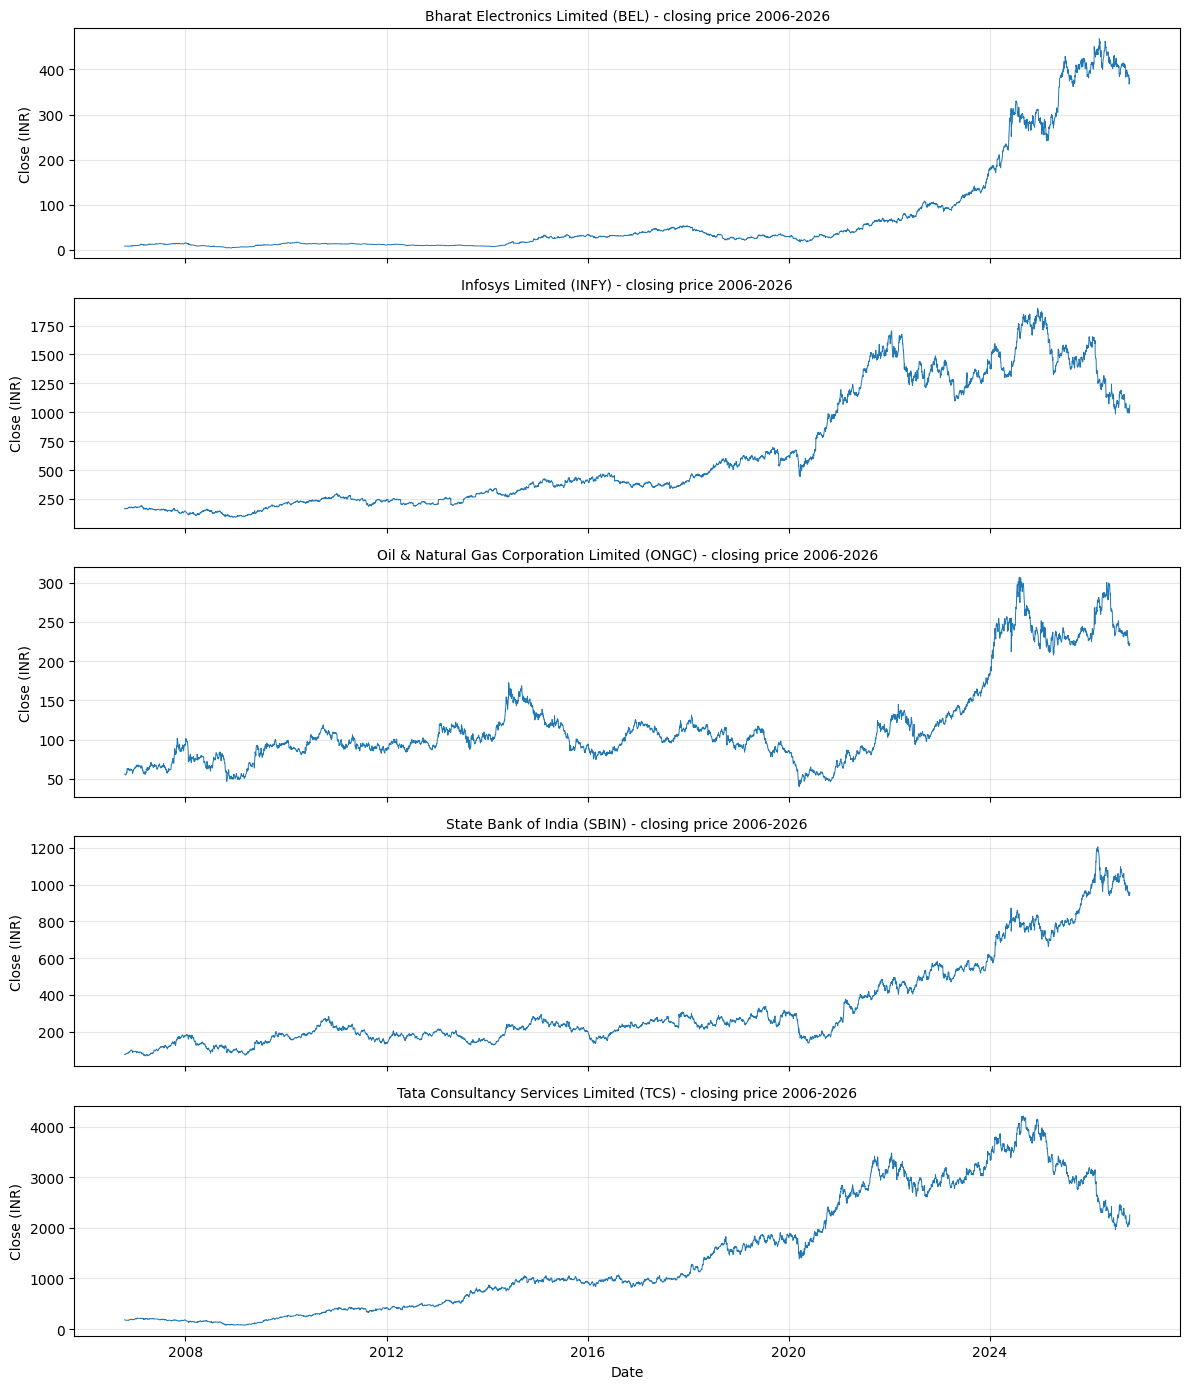

In [4]:
# Closing price history of all five stocks
fig, axes = plt.subplots(5, 1, figsize=(12, 14), sharex=True)
for ax, (sym, g) in zip(axes, df.groupby('symbol')):
    ax.plot(g['price_date'], g['close'], lw=0.7)
    ax.set_ylabel('Close (INR)')
    ax.set_title(f"{g['stock'].iloc[0]} ({sym}) - closing price 2006-2026", fontsize=10)
    ax.grid(alpha=0.3)
axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.savefig('figures/fig1_closing_prices.png', dpi=110)
plt.show()

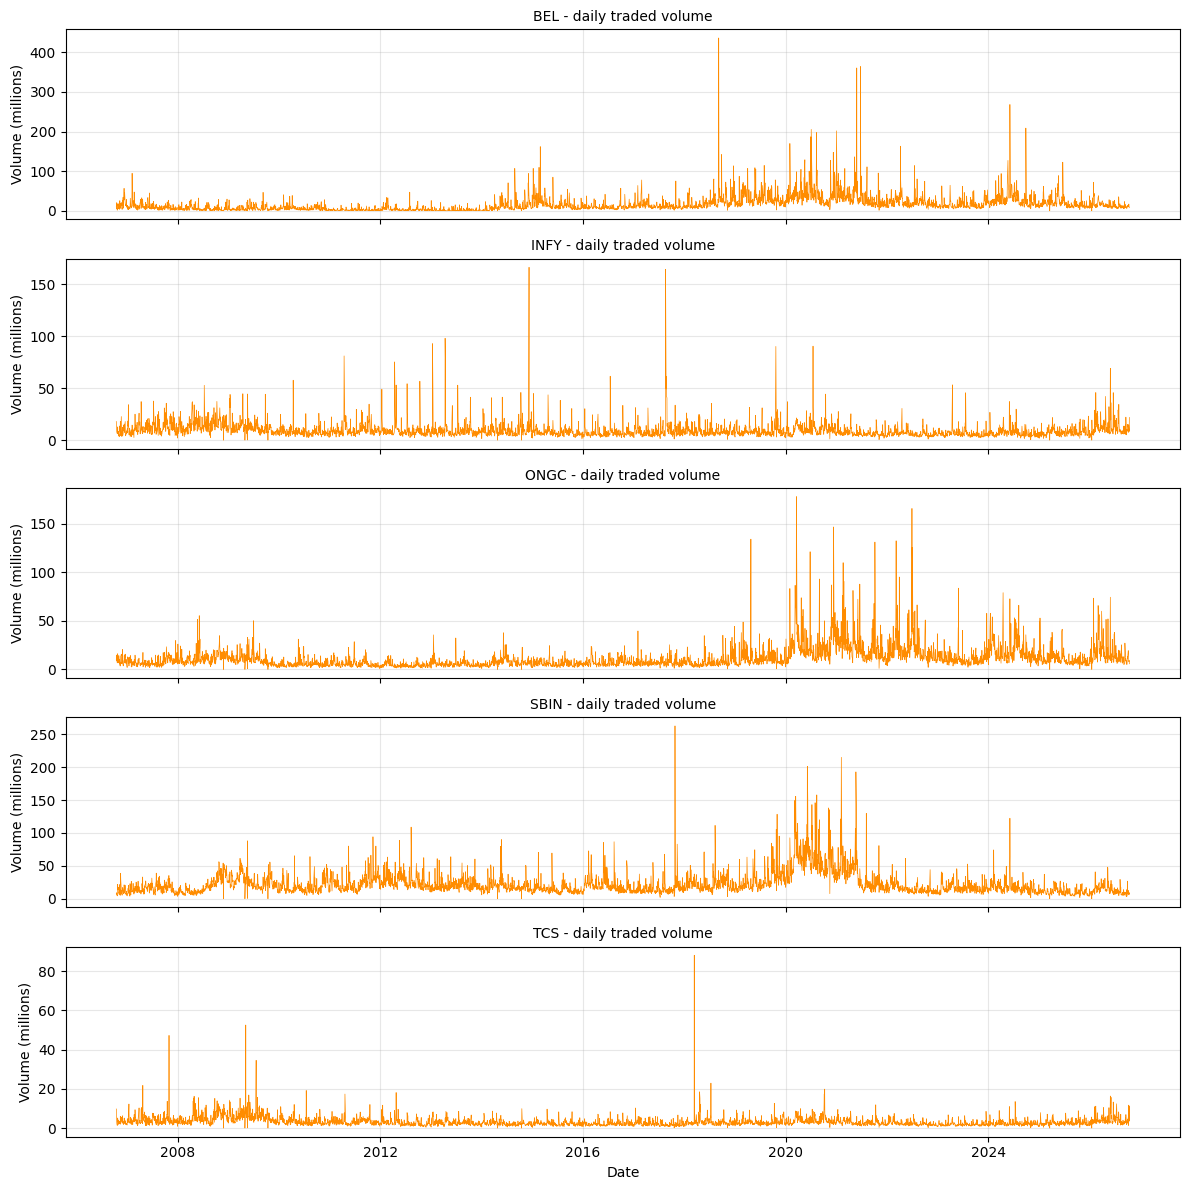

In [5]:
# Trading volume history
fig, axes = plt.subplots(5, 1, figsize=(12, 12), sharex=True)
for ax, (sym, g) in zip(axes, df.groupby('symbol')):
    ax.plot(g['price_date'], g['volume'] / 1e6, lw=0.5, color='darkorange')
    ax.set_ylabel('Volume (millions)')
    ax.set_title(f'{sym} - daily traded volume', fontsize=10)
    ax.grid(alpha=0.3)
axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.savefig('figures/fig2_volumes.png', dpi=110)
plt.show()

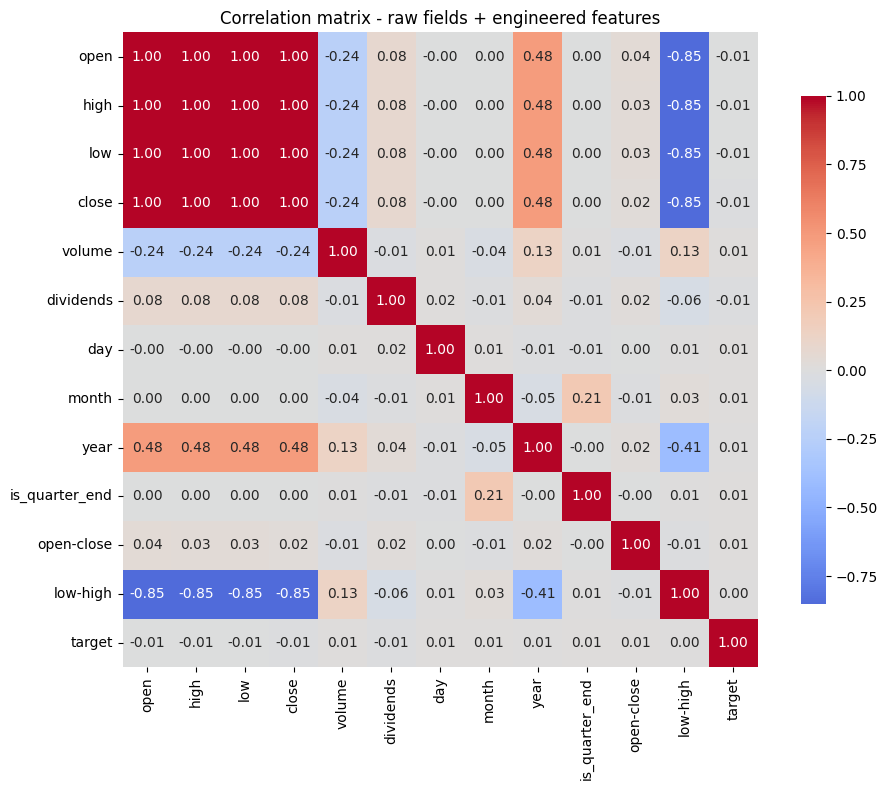

Correlation of each feature with target:
month             0.0135
volume            0.0106
day               0.0106
open-close        0.0106
is_quarter_end    0.0092
dividends        -0.0084
year              0.0055
close            -0.0054
low              -0.0053
high             -0.0053
open             -0.0052
low-high          0.0026
Name: target, dtype: float64


In [6]:
# Correlation heatmap of the numeric fields and engineered features
num_cols = ['open', 'high', 'low', 'close', 'volume', 'dividends', 'day', 'month', 'year', 'is_quarter_end', 'open-close', 'low-high', 'target']
corr = df_model[num_cols].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, cbar_kws={'shrink': 0.8})
plt.title('Correlation matrix - raw fields + engineered features')
plt.tight_layout()
plt.savefig('figures/fig3_correlation.png', dpi=110)
plt.show()
print('Correlation of each feature with target:')
print(corr['target'].drop('target').sort_values(key=abs, ascending=False).round(4))

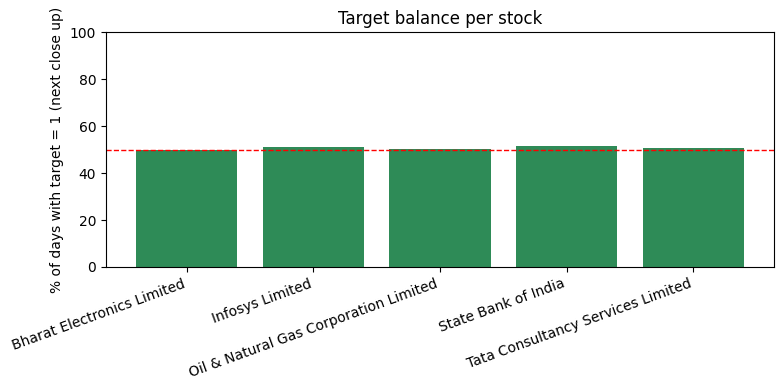

                                       count  up_days(%)
stock                                                   
Bharat Electronics Limited              4930        49.8
Infosys Limited                         4930        51.1
Oil & Natural Gas Corporation Limited   4930        50.3
State Bank of India                     4930        51.7
Tata Consultancy Services Limited       4930        50.5


In [7]:
# Target class balance per stock
balance = df_model.groupby('stock')['target'].agg(['mean', 'count'])
balance['up_days(%)'] = (balance['mean'] * 100).round(1)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(balance.index, balance['mean'] * 100, color='seagreen')
ax.axhline(50, color='red', ls='--', lw=1, label='50%')
ax.set_ylabel('% of days with target = 1 (next close up)')
ax.set_title('Target balance per stock')
ax.set_ylim(0, 100)
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.savefig('figures/fig4_target_balance.png', dpi=110)
plt.show()
print(balance[['count', 'up_days(%)']])

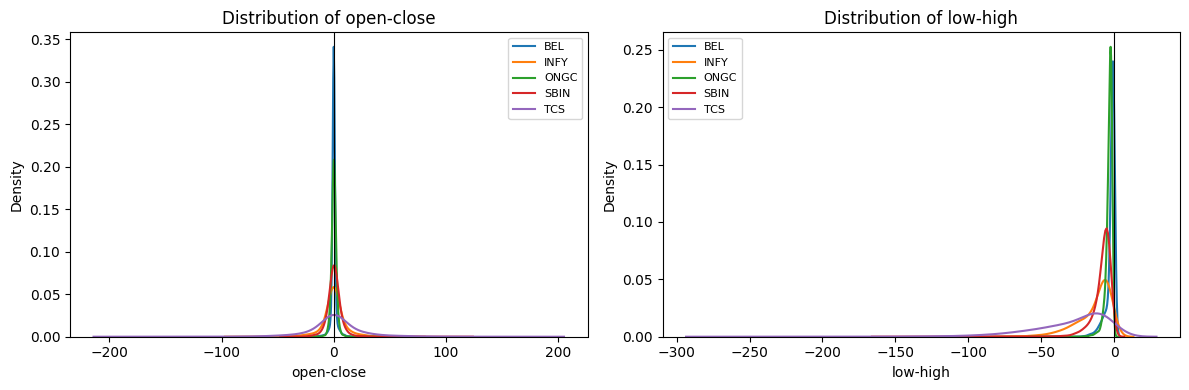

In [8]:
# Distribution of the two key model features
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, color in zip(axes, ['open-close', 'low-high'], ['steelblue', 'indianred']):
    for sym, g in df_model.groupby('symbol'):
        sns.kdeplot(g[col], ax=ax, label=sym, bw_adjust=2)
    ax.axvline(0, color='black', lw=0.8)
    ax.set_title(f'Distribution of {col}')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('figures/fig5_feature_distributions.png', dpi=110)
plt.show()

## 4. Train the model - PyTorch TabNet

One TabNet classifier is trained for **all** the stocks, exactly as specified:
- **Prediction variables:** `stock` (categorical), `open-close`, `low-high`, `is_quarter_end`
- **Predicted variable:** `target`

A time-aware split is used: for each stock the **last 20% of its days** form the validation set, so the model is always evaluated on days *after* the days it trained on (no look-ahead leakage). The final training row of each stock is **purged from both sets**, because its `target` label would otherwise be computed from the first validation day's close.

In [9]:
from pytorch_tabnet.tab_model import TabNetClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, confusion_matrix

feature_cols = ['stock', 'open-close', 'low-high', 'is_quarter_end']

# categorical encoding of the stock name (TabNet native categorical support)
stocks = sorted(df_model['stock'].unique())
stock2idx = {s: i for i, s in enumerate(stocks)}
df_model['stock_idx'] = df_model['stock'].map(stock2idx)

X_all = df_model[['stock_idx', 'open-close', 'low-high', 'is_quarter_end']].values.astype(np.float32)
X_all[:, 0] = X_all[:, 0].astype(int)  # categorical column
y_all = df_model['target'].values.astype(int)

# time-aware split: last 20% of each stock's timeline -> validation
train_mask = np.zeros(len(df_model), dtype=bool)
for sym, g in df_model.groupby('symbol'):
    cut = g['price_date'].quantile(0.8)
    train_mask |= ((df_model['symbol'] == sym) & (df_model['price_date'] <= cut)).values

# purge the final training row of each stock: its target label is computed from the
# first validation day's close, so keeping it would leak validation-period information
purge_idx = df_model[train_mask].groupby('symbol')['price_date'].idxmax()
purged = np.zeros(len(df_model), dtype=bool)
purged[purge_idx] = True
train_mask[purge_idx] = False
print('Purged', len(purge_idx), 'boundary training rows whose labels referenced validation-period closes')

X_train, y_train = X_all[train_mask], y_all[train_mask]
X_valid, y_valid = X_all[(~train_mask) & (~purged)], y_all[(~train_mask) & (~purged)]  # purged rows excluded from both sets
print('Train rows:', len(X_train), '| Validation rows:', len(X_valid))
print('Features:', feature_cols)

clf = TabNetClassifier(
    cat_idxs=[0], cat_dims=[len(stocks)], cat_emb_dim=3,
    n_d=16, n_a=16, n_steps=5, gamma=1.5,
    lambda_sparse=1e-4,
    optimizer_fn=torch.optim.Adam, optimizer_params=dict(lr=2e-2),
    mask_type='entmax', seed=SEED, verbose=1,
)
clf.fit(
    X_train, y_train,
    eval_set=[(X_valid, y_valid)], eval_name=['valid'], eval_metric=['accuracy', 'auc'],
    max_epochs=100, patience=15, batch_size=1024, virtual_batch_size=256,
)

Purged 5 boundary training rows whose labels referenced validation-period closes
Train rows: 19715 | Validation rows: 4930
Features: ['stock', 'open-close', 'low-high', 'is_quarter_end']


/home/sandbox/.local/lib/python3.10/site-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 0.86399 | valid_accuracy: 0.48438 | valid_auc: 0.48517 |  0:00:00s


epoch 1  | loss: 0.7073  | valid_accuracy: 0.49026 | valid_auc: 0.49037 |  0:00:00s


epoch 2  | loss: 0.69624 | valid_accuracy: 0.49939 | valid_auc: 0.50665 |  0:00:01s


epoch 3  | loss: 0.6964  | valid_accuracy: 0.49533 | valid_auc: 0.49533 |  0:00:01s


... (16 outputs left out)

epoch 20 | loss: 0.69245 | valid_accuracy: 0.50243 | valid_auc: 0.49415 |  0:00:07s


epoch 21 | loss: 0.69241 | valid_accuracy: 0.50223 | valid_auc: 0.50201 |  0:00:07s


epoch 22 | loss: 0.69238 | valid_accuracy: 0.48905 | valid_auc: 0.49407 |  0:00:08s

Early stopping occurred at epoch 22 with best_epoch = 7 and best_valid_auc = 0.51832


/home/sandbox/.local/lib/python3.10/site-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


Validation accuracy: 0.5034
Validation ROC AUC : 0.5183

              precision    recall  f1-score   support

    Sell (0)       0.50      0.69      0.58      2444
     Buy (1)       0.51      0.32      0.40      2486

    accuracy                           0.50      4930
   macro avg       0.51      0.51      0.49      4930
weighted avg       0.51      0.50      0.49      4930



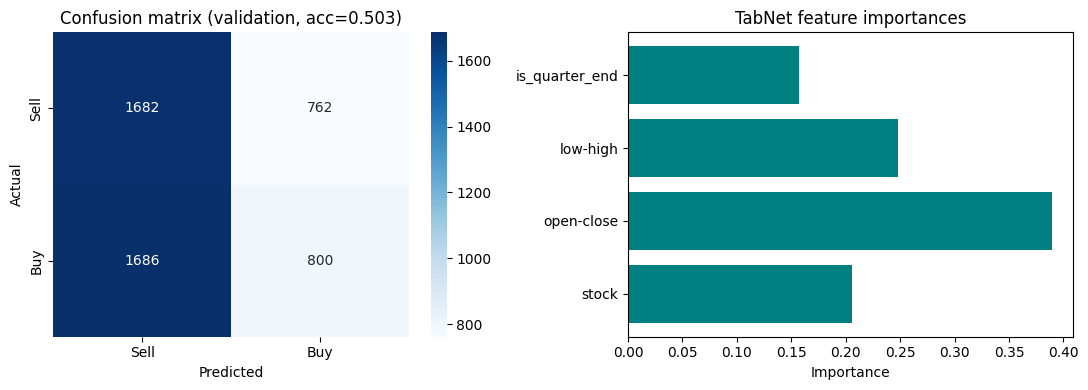

Feature importances: {'stock': np.float64(0.206), 'open-close': np.float64(0.389), 'low-high': np.float64(0.248), 'is_quarter_end': np.float64(0.157)}


In [10]:
# Validation performance
proba_valid = clf.predict_proba(X_valid)[:, 1]
pred_valid = clf.predict(X_valid)
acc = accuracy_score(y_valid, pred_valid)
auc = roc_auc_score(y_valid, proba_valid)
print(f'Validation accuracy: {acc:.4f}')
print(f'Validation ROC AUC : {auc:.4f}')
print()
print(classification_report(y_valid, pred_valid, target_names=['Sell (0)', 'Buy (1)']))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
cm = confusion_matrix(y_valid, pred_valid)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Sell', 'Buy'], yticklabels=['Sell', 'Buy'])
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')
axes[0].set_title(f'Confusion matrix (validation, acc={acc:.3f})')

imp = clf.feature_importances_
axes[1].barh(feature_cols, imp, color='teal')
axes[1].set_title('TabNet feature importances')
axes[1].set_xlabel('Importance')
plt.tight_layout()
plt.savefig('figures/fig6_model_results.png', dpi=110)
plt.show()
print('Feature importances:', dict(zip(feature_cols, imp.round(3))))

## 5. Prediction on `nifty50_prd2`

The prediction file holds **one row per stock for 14-10-2026**. The same feature engineering is applied and the trained TabNet predicts `target`; the output is mapped to **Buy (1) / Sell (0)** as per the sample output format.

The model used here is exactly the one trained on the 80% training window above - there is **no refit on the full history**, so the validation metrics describe the same model that produces these signals. Its features use only each stock's own 14-10-2026 row, so no future data is involved.

In [11]:
pred_df = pd.read_csv(PRED_URL, header=None, names=cols)
pred_df['price_date'] = pd.to_datetime(pred_df['price_date'], format='%Y-%m-%d')
pred_df['day'] = pred_df['price_date'].dt.day
pred_df['month'] = pred_df['price_date'].dt.month
pred_df['year'] = pred_df['price_date'].dt.year
pred_df['is_quarter_end'] = np.where(pred_df['month'] % 3 == 0, 1, 0)
pred_df['open-close'] = pred_df['open'] - pred_df['close']
pred_df['low-high'] = pred_df['low'] - pred_df['high']
pred_df['stock_idx'] = pred_df['stock'].map(stock2idx)

X_pred = pred_df[['stock_idx', 'open-close', 'low-high', 'is_quarter_end']].values.astype(np.float32)
pred_labels = clf.predict(X_pred)
pred_proba = clf.predict_proba(X_pred)[:, 1]

pred_df['target_pred'] = pred_labels
pred_df['Signal'] = np.where(pred_df['target_pred'] == 1, 'Buy', 'Sell')
pred_df['Buy_probability'] = pred_proba.round(3)

result = pred_df[['stock', 'Signal', 'Buy_probability']].sort_values('stock').reset_index(drop=True)
print('=== FINAL OUTPUT (Target = 1 : Buy, Target = 0 : Sell) ===')
for _, r in result.iterrows():
    print(f'{r["stock"]:<40} {r["Signal"]}')
result

=== FINAL OUTPUT (Target = 1 : Buy, Target = 0 : Sell) ===
Bharat Electronics Limited               Sell
Infosys Limited                          Sell
Oil & Natural Gas Corporation Limited    Sell
State Bank of India                      Buy
Tata Consultancy Services Limited        Sell


,stock,Signal,Buy_probability
0,Bharat Electronics Limited,Sell,0.486
1,Infosys Limited,Sell,0.497
2,Oil & Natural Gas Corporation Limited,Sell,0.480
3,State Bank of India,Buy,0.515
4,Tata Consultancy Services Limited,Sell,0.370


In [12]:
# Save the output in the specified format
out = result[['stock', 'Signal']]
out.to_csv('prediction_output.csv', index=False)
print(out.to_string(index=False))

# Persist headline results for the report
report = {
    'train_rows': int(len(X_train)), 'valid_rows': int(len(X_valid)),
    'valid_accuracy': round(float(acc), 4), 'valid_auc': round(float(auc), 4),
    'feature_importances': {k: round(float(v), 4) for k, v in zip(feature_cols, imp)},
    'predictions': out.to_dict('records'),
    'buy_probabilities': {r['stock']: float(r['Buy_probability']) for _, r in result.iterrows()},
}
with open('results_summary.json', 'w') as f:
    json.dump(report, f, indent=2)
print()
print('Saved prediction_output.csv and results_summary.json')

                                stock Signal
           Bharat Electronics Limited   Sell
                      Infosys Limited   Sell
Oil & Natural Gas Corporation Limited   Sell
                  State Bank of India    Buy
    Tata Consultancy Services Limited   Sell

Saved prediction_output.csv and results_summary.json


## 6. Interpretation

- The dataset covers **5 NIFTY50 stocks** (SBIN, ONGC, BEL, INFY, TCS) with ~4,931 trading days each from **Oct 2006 to Oct 2026** (20 years).
- The engineered feature `open-close` is positive on days the stock **fell** intraday (open above close) and `low-high` is always <= 0, its magnitude showing the day's trading range. `is_quarter_end` flags months 3, 6, 9 and 12.
- The target is close to balanced (~50% up-days per stock), so accuracy is a meaningful metric for this setup.
- Validation is time-aware: the most recent 20% of each stock's timeline (2022-2026) is held out, and the boundary training rows whose labels would have touched validation-period prices were purged. The metrics therefore describe genuinely unseen future days.
- In this run the model scored only marginally above the 50% coin-flip level on those held-out days. With only the four specified same-day features, it found very little exploitable next-day signal - consistent with the near-zero feature/target correlations seen in the EDA.
- TabNet's feature importances show which of the four prediction variables the model used most (`open-close` first). The final signals above are its Buy/Sell call for each stock for the next trading day after **14-10-2026**: real model output, but low-confidence directional leans rather than strong trading calls. A Buy means the model predicts the next close to be higher than the close of 14-10-2026.